# Qualidade de Energia 1

Importando bibliotecas,definindo constantes e funções

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt 
deg = np.pi/180
rad = 180/np.pi
freq1 = 60
omeg1 = 2*np.pi*freq1
nr_ciclos = 10
nr_pts_ciclo = 2**7

In [2]:
t = np.linspace(0,nr_ciclos/freq1,nr_ciclos*nr_pts_ciclo);
#print(t)
#print(len(t))

## Definindo harmônicos de corrente e tensão
Aqui deveremos substituir pela leitura dos dados

In [3]:
nr_harm = 16
v = np.zeros([nr_harm,len(t)])
i = np.zeros([nr_harm,len(t)])

In [4]:
va = np.zeros(len(t))
ia = np.zeros(len(t))
for h in range(nr_harm):
    if( h > 0 ):
        v[[h][:]] = 1.2/(h**3) * np.cos(h*(omeg1*t -  0*deg))
        i[[h][:]] = 1.0/(h   ) * np.cos(h*(omeg1*t - 30*deg))
        va[:] = va[:] + v[[h][:]]
        ia[:] = ia[:] + i[[h][:]]

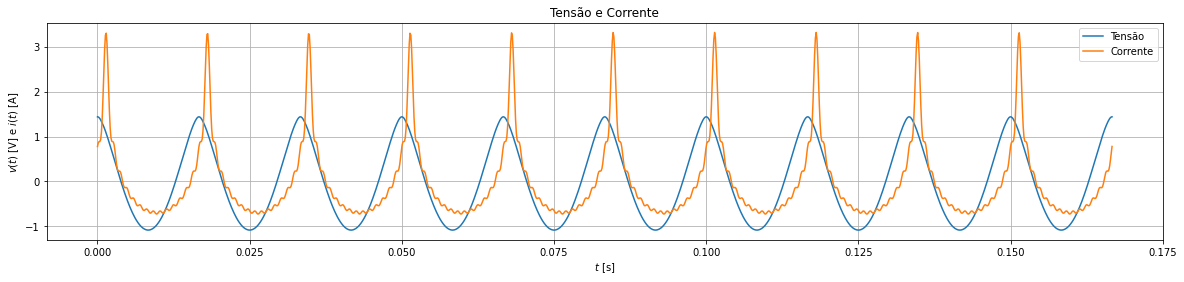

In [5]:
plt.figure(figsize=(20, 4))
plt.plot(t,va,label='Tensão')
plt.plot(t,ia,label='Corrente')
plt.grid()
plt.title(label='Tensão e Corrente')
plt.xlabel('$t$ [s]')
plt.ylabel('$v(t)$ [V] e $i(t)$ [A]')
plt.legend()
plt.show()

## Cálculo dos Harmônicos de Tensão e Corrente

In [6]:
npts = len(t);
Va = np.fft.fft(va)
mod_Va = ( np.abs(Va) )
mod_Va = 2/npts * mod_Va
arg_Va = np.angle(Va)

Ia = np.fft.fft(ia)
mod_Ia = ( np.abs(Ia) )
mod_Ia = 2/npts * mod_Ia
arg_Ia = np.angle(Ia)

In [16]:
dtempo = t[1] - t[0]
dfreq = 1 / t[len(t)-1]
h = np.arange(0, npts/2, 1)
FREQ = dfreq * h

dfreq
t[len(t)-1]

0.16666666666666666

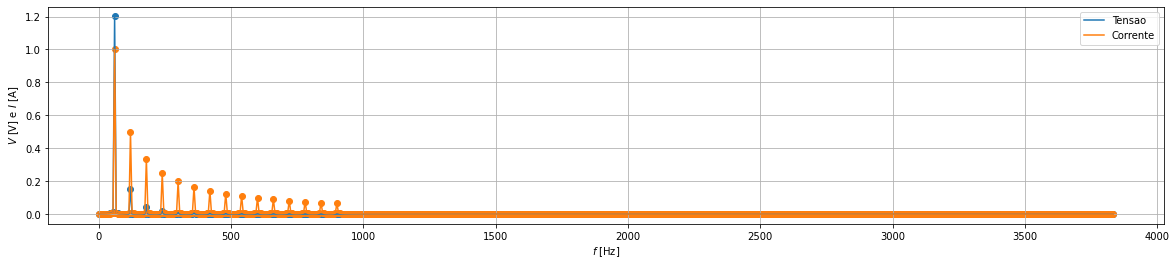

In [8]:
plt.figure(figsize=(20, 4))
plt.plot(FREQ,mod_Va[0:int(npts/2)],label='Tensao')
plt.scatter(FREQ,mod_Va[0:int(npts/2)])
plt.plot(FREQ,mod_Ia[0:int(npts/2)],label='Corrente')
plt.scatter(FREQ,mod_Ia[0:int(npts/2)])
plt.xlabel('$f$ [Hz]')
plt.ylabel('$V$ [V] e $I$ [A]')
plt.grid()
plt.legend()
plt.show()

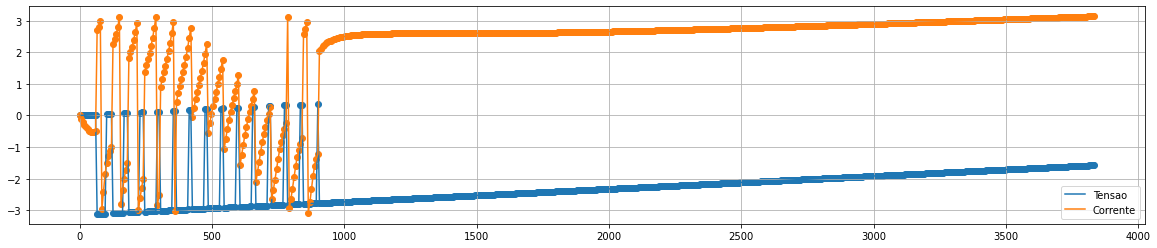

In [9]:
plt.figure(figsize=(20, 4))
plt.plot(FREQ,arg_Va[0:int(npts/2)],label='Tensao')
plt.scatter(FREQ,arg_Va[0:int(npts/2)])
plt.plot(FREQ,arg_Ia[0:int(npts/2)],label='Corrente')
plt.scatter(FREQ,arg_Ia[0:int(npts/2)])
plt.grid()
plt.legend()
plt.show()

## Potências
Calculada a potência complexa para cada harmônico por:
$${S_h} = {\dot V_h}{\dot I_h}$$

In [10]:
Sa = 0.5 * mod_Va * mod_Ia * np.exp(-1j*(arg_Ia - arg_Va))
Pa = np.real(Sa)
Qa = np.imag(Sa)
Pa[nr_ciclos]

0.5200947564179169

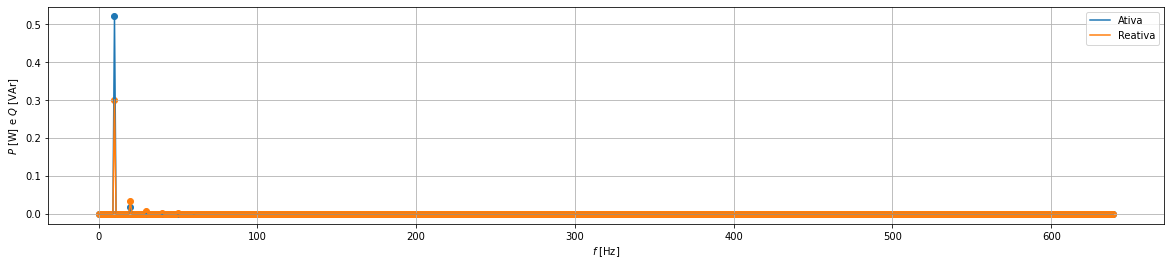

In [11]:
plt.figure(figsize=(20, 4))
plt.plot(h,Pa[0:int(npts/2)],label='Ativa')
plt.scatter(h,Pa[0:int(npts/2)])
plt.plot(h,Qa[0:int(npts/2)],label='Reativa')
plt.scatter(h,Qa[0:int(npts/2)])
plt.xlabel('$f$ [Hz]')
plt.ylabel('$P$ [W] e $Q$ [VAr]')
plt.grid()
plt.legend()
plt.show()

## Fatores de Deslocamento, Distorção e Potência

In [12]:
FDesl = np.cos(arg_Va - arg_Ia)
print("Fator de Deslocamento da Fundamental FDesl1= ",FDesl[nr_ciclos])

Fator de Deslocamento da Fundamental FDesl1=  0.8658780124275244


In [13]:
temp = int(npts/2)

DHT_I = np.sqrt(np.dot(mod_Ia[0:temp],mod_Ia[0:temp]) - mod_Ia[nr_ciclos]*mod_Ia[nr_ciclos]) / mod_Ia[nr_ciclos]
FDist_I = 1 / np.sqrt( 1 + DHT_I**2 )
print("Fator de distorção da corrente FDist_I = ",FDist_I)

DHT_V = np.sqrt(np.dot(mod_Va[0:temp],mod_Va[0:temp]) - mod_Va[nr_ciclos]*mod_Va[nr_ciclos]) / mod_Va[nr_ciclos]
FDist_V = 1 / np.sqrt( 1 + DHT_V**2 )
print("Fator de distorção da tensão FDist_V = ",FDist_V)

Fator de distorção da corrente FDist_I =  0.7958486498212088
Fator de distorção da tensão FDist_V =  0.9914018765648777


In [14]:
FPot = FDesl[nr_ciclos] * FDist_I * FDist_V
print("Fator de Potência Verdadeiro FPot = ",FPot)

Fator de Potência Verdadeiro FPot =  0.6831828127708371
